Dataset saved to: pump_imbalance_frequency_spectrum.csv


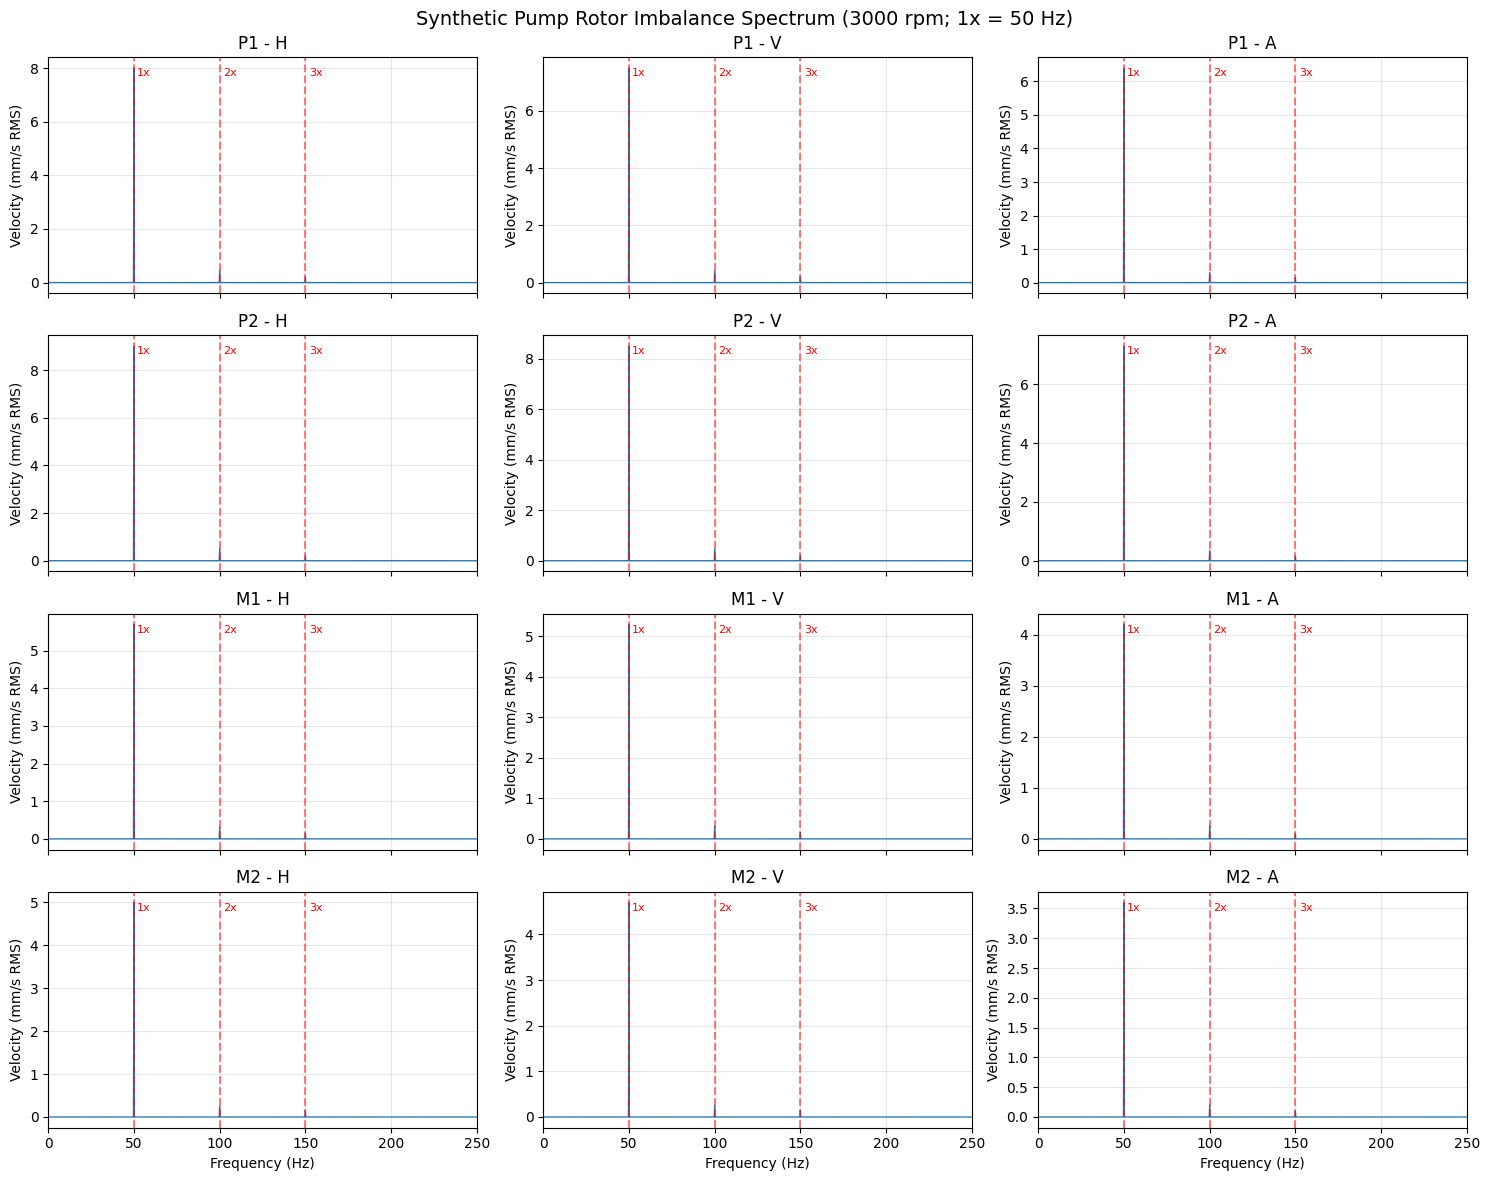

Plot saved to: pump_imbalance_frequency_spectrum.png


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Machine and measurement setup
# -----------------------------
rng = np.random.default_rng(seed=42)

machine_number = "M1201"
rpm = 3000
running_frequency_hz = rpm / 60  # 50 Hz

measurement_timestamp = pd.Timestamp.now().isoformat(timespec="seconds")

# Sampling setup: frequency resolution = 1 / duration = 0.25 Hz
sample_rate_hz = 2048
duration_seconds = 4
time = np.arange(0, duration_seconds, 1 / sample_rate_hz)

max_frequency_hz = 500
plot_max_frequency_hz = 250
noise_standard_deviation = 0.05  # mm/s

# -----------------------------
# Simulated RMS harmonic amplitudes
# -----------------------------
# Values are illustrative velocity RMS amplitudes in mm/s.
# Order 1 = 50 Hz; order 2 = 100 Hz; order 3 = 150 Hz.
# The pump has stronger radial 1x vibration; lower vibration is
# simulated at the motor bearings due to transmission.
harmonic_rms = {
    "P1": {
        "H": {1: 8.0, 2: 0.45, 3: 0.20},
        "V": {1: 7.5, 2: 0.40, 3: 0.20},
        "A": {1: 6.4, 2: 0.30, 3: 0.15},
    },
    "P2": {
        "H": {1: 9.0, 2: 0.50, 3: 0.20},
        "V": {1: 8.5, 2: 0.45, 3: 0.20},
        "A": {1: 7.3, 2: 0.35, 3: 0.15},
    },
    "M1": {
        "H": {1: 5.7, 2: 0.30, 3: 0.15},
        "V": {1: 5.3, 2: 0.30, 3: 0.15},
        "A": {1: 4.2, 2: 0.25, 3: 0.10},
    },
    "M2": {
        "H": {1: 5.0, 2: 0.25, 3: 0.15},
        "V": {1: 4.7, 2: 0.25, 3: 0.15},
        "A": {1: 3.6, 2: 0.20, 3: 0.10},
    },
}

def create_velocity_signal(order_amplitudes):
    """Create a synthetic velocity signal in mm/s."""
    signal = np.zeros_like(time)

    for order, rms_amplitude in order_amplitudes.items():
        frequency_hz = order * running_frequency_hz
        peak_amplitude = rms_amplitude * np.sqrt(2)

        signal += peak_amplitude * np.sin(
            2 * np.pi * frequency_hz * time
        )

    signal += rng.normal(
        loc=0.0,
        scale=noise_standard_deviation,
        size=len(time)
    )

    return signal

def calculate_rms_spectrum(signal):
    """Calculate a single-sided RMS amplitude spectrum."""
    fft_values = np.fft.rfft(signal)
    frequencies_hz = np.fft.rfftfreq(
        len(signal),
        d=1 / sample_rate_hz
    )

    peak_amplitude = 2 * np.abs(fft_values) / len(signal)

    # Do not double the DC or Nyquist components
    peak_amplitude[0] /= 2
    if len(signal) % 2 == 0:
        peak_amplitude[-1] /= 2

    rms_amplitude = peak_amplitude / np.sqrt(2)
    return frequencies_hz, rms_amplitude

# -----------------------------
# Generate spectra and CSV rows
# -----------------------------
records = []
spectra_for_plot = {}

for location, directions in harmonic_rms.items():
    for direction, order_amplitudes in directions.items():
        signal = create_velocity_signal(order_amplitudes)
        frequencies_hz, spectrum_rms = calculate_rms_spectrum(signal)

        overall_rms = np.sqrt(np.mean(signal ** 2))
        spectra_for_plot[(location, direction)] = (
            frequencies_hz,
            spectrum_rms
        )

        for frequency_hz, amplitude_rms in zip(
            frequencies_hz,
            spectrum_rms
        ):
            if frequency_hz <= max_frequency_hz:
                records.append({
                    "Machine_number": machine_number,
                    "Timestamp": measurement_timestamp,
                    "RPM": rpm,
                    "Running_frequency_Hz": running_frequency_hz,
                    "Location": location,
                    "Direction": direction,
                    "Frequency_Hz": round(float(frequency_hz), 3),
                    "Frequency_Order": round(
                        float(frequency_hz / running_frequency_hz), 3
                    ),
                    "Velocity_RMS_mm_s": round(float(amplitude_rms), 5),
                    "Overall_RMS_mm_s": round(float(overall_rms), 3),
                })

dataset = pd.DataFrame(records)

csv_file = "pump_imbalance_frequency_spectrum.csv"
dataset.to_csv(csv_file, index=False)
print(f"Dataset saved to: {csv_file}")

# -----------------------------
# Plot spectra
# -----------------------------
locations = ["P1", "P2", "M1", "M2"]
directions = ["H", "V", "A"]

fig, axes = plt.subplots(
    nrows=len(locations),
    ncols=len(directions),
    figsize=(15, 12),
    sharex=True
)

for row_index, location in enumerate(locations):
    for col_index, direction in enumerate(directions):
        ax = axes[row_index, col_index]
        frequencies_hz, spectrum_rms = spectra_for_plot[
            (location, direction)
        ]

        visible = frequencies_hz <= plot_max_frequency_hz
        ax.plot(
            frequencies_hz[visible],
            spectrum_rms[visible],
            linewidth=0.9
        )

        # Mark 1x, 2x, and 3x running-speed frequencies
        for order in (1, 2, 3):
            frequency = order * running_frequency_hz
            ax.axvline(
                frequency,
                color="red",
                linestyle="--",
                alpha=0.5
            )
            ax.text(
                frequency + 2,
                0.92,
                f"{order}x",
                transform=ax.get_xaxis_transform(),
                color="red",
                fontsize=8
            )

        ax.set_title(f"{location} - {direction}")
        ax.set_ylabel("Velocity (mm/s RMS)")
        ax.set_xlim(0, plot_max_frequency_hz)
        ax.grid(True, alpha=0.3)

for ax in axes[-1, :]:
    ax.set_xlabel("Frequency (Hz)")

fig.suptitle(
    f"Synthetic Pump Rotor Imbalance Spectrum "
    f"({rpm} rpm; 1x = {running_frequency_hz:.0f} Hz)",
    fontsize=14
)

plt.tight_layout()

plot_file = "pump_imbalance_frequency_spectrum.png"
plt.savefig(plot_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_file}")